# <center> 🏋️‍ Fine-Tune LLM 🏋️‍♂️
---
    
**LoRA** makes a small change in the fine-tuning process. Instead of computing gradients for all the entries in W (which is huge), and updating all the parameters, it’s algorithm works as follows:
1. Freeze the original parameters $W$ at the start of fine-tuning.
2. Decomposes $W$ into two smaller matrices $A$ and $B$, and update these two small matrices during fine-tuning. The decomposed matrices are significantly smaller in size than the original weight matrix $W$, and can easily fit into the memory. The decomposition is done in such a way that we can regenerate $W$ from $A$ and $B$. Basically $A$ and $B$ are LD, so the resulting LI matrix (That it is $W$) can be composed from $A$ and $B$.
3. Once fine-tuning is completed, the smaller matrices $A$ and $B$ get adapted for the specific task.
4. The important thing to note here is that the pretrained weights are not changed during this process as they were frozen by LoRA. The question arises now that how do we use the adapted matrices $A$ and $B$ to do the inference on a new input. Previously with normal finetuning/pretraining, if input to the model was $x$, the output of layer used to be $W\times x$. But after fine-tuning the model with LoRA, the updated inference equation is:

$$h=W x + \Delta W x = W x + (B\times A) x$$
    
...where $x$ is the input, $W$ represents model parameters, $B$ and $A$ represent low-rank adapters trained during LoRA fine-tuning.
    
> The amount of memory saved depends on the rank $r$, a hyperparameter. For instance, if $\Delta W$ has 10,000 rows and 20,000 columns, it holds 200,000,000 parameters. Choosing $A$ and $B$ with $r=8$, $A$ would have 10,000 rows and 8 columns, and $B$ would have 8 rows and 20,000 columns, resulting in 10,000×8 + 8×20,000 = 240,000 parameters, which is approximately 830 times fewer than 200,000,000.

In [1]:
!pip install torch==2.3.0 torchvision==0.18.0 torchaudio==2.3.0 --index-url https://download.pytorch.org/whl/cu121 -q

In [2]:
!pip install "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git" -q


[notice] A new release of pip available: 22.2.2 -> 24.2
[notice] To update, run: pip install --upgrade pip


In [3]:
!pip install --no-deps "xformers<0.0.27" "trl<0.9.0" peft accelerate bitsandbytes -q


[notice] A new release of pip available: 22.2.2 -> 24.2
[notice] To update, run: pip install --upgrade pip


In [4]:
!pip install seaborn -q


[notice] A new release of pip available: 22.2.2 -> 24.2
[notice] To update, run: pip install --upgrade pip


In [5]:
import torch
from trl import SFTTrainer
from datasets import load_dataset
from transformers import TrainingArguments, TextStreamer
from unsloth.chat_templates import get_chat_template
from unsloth import FastLanguageModel, is_bfloat16_supported
import pandas as pd
import sklearn
import triton
import os
import boto3
from tqdm import tqdm
import json
import re
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import AutoTokenizer, TrainingArguments,BitsAndBytesConfig,AutoModelForCausalLM
import transformers
from trl import SFTTrainer

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


### Get env ready
Lets set the bucket name and model name where you have all your datasets

In [6]:
# Enter the bucket and model name
bucket_name = input("Enter bucket name:")
prefix = input("Enter prefix (region):")
model_name = input("Enter model name:")

Enter bucket name: text-classification
Enter prefix (region): datasets/labeled/fine-tune
Enter model name: ISO-500


In [7]:
class bcolors:
    HEADER = '\033[95m'
    OKBLUE = '\033[94m'
    OKCYAN = '\033[96m'
    OKGREEN = '\033[92m'
    WARNING = '\033[93m'
    FAIL = '\033[91m'
    ENDC = '\033[0m'
    BOLD = '\033[1m'
    UNDERLINE = '\033[4m'

print(f"{bcolors.HEADER} ---ENV REPORT-- {bcolors.ENDC}")
if torch.cuda.is_available():
    print(f"{bcolors.OKGREEN} CUDA {bcolors.ENDC} cores ")
    print(f"{bcolors.BOLD} GPUs: {torch.cuda.device_count()} {bcolors.ENDC}\n")
    gpu_stats = torch.cuda.get_device_properties(0)
    print(f"{bcolors.BOLD}Graphic Card: {gpu_stats.name}{bcolors.ENDC}\n" )
else:
    print(f"{bcolors.OKBLUE} Using CPU cores {bcolors.ENDC}")

print(f"{bcolors.OKCYAN}LIBRARIES{bcolors.ENDC}")
print(f"PyTorch version: {torch.__version__}")
print(f"Triton version: {triton.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"scikit-learn version: {sklearn.__version__}")

 ---ENV REPORT-- 
 CUDA  cores 
 GPUs: 1 

Graphic Card: NVIDIA A10G

LIBRARIES
PyTorch version: 2.3.0+cu121
Triton version: 2.3.0
Pandas version: 2.2.2
scikit-learn version: 1.4.2


In [8]:
def check_cuda_memory():
    gpu_stats = torch.cuda.get_device_properties(0)
    start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
    max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
    print(f"{bcolors.BOLD} {start_gpu_memory}GB {bcolors.ENDC} reserved of {bcolors.BOLD} {max_memory}GB {bcolors.ENDC} VRAM")
    return start_gpu_memory

### The rank in LoRa
A higher rank means a greater number of trainable parameters in our model, making fine-tuning more memory intensive. However, higher ranks retain more information from the original weight matrix, as the decomposed matrices themselves are large and capture most of the essence of W (i.e., the model becomes more expressive). We can say that, as the rank increases, LORA essentially converges toward normal fine-tuning.

### Alpha in LoRa
A higher “alpha” would place more emphasis on the low-rank structure or regularization, while a lower “alpha” would reduce its influence, making the model rely more on the original parameters. Adjusting “alpha” helps in striking a balance between fitting the data and preventing overfitting by regularizing the model.

As a rule of thumb, it’s usually common to choose an alpha that is twice as large as the rank when fine-tuning LLMs (note that this is different when working with diffusion models).

- Batch size refers to the number of training samples processed before the model's internal parameters (weights) are updated.
- Gradient accumulation is a technique where gradients are accumulated over several batches before updating the model weights.
- This effectively increases the batch size without needing extra memory. For example, if you have a batch size of 2 and accumulate gradients over 4 steps, it is equivalent to having a batch size of 8 in terms of gradient calculation

### Training Parameters

During training, instead of updating the model weights after each batch, the gradients are accumulated over the specified number of batches (accumulation steps). After these steps, the accumulated gradients are used to update the model weights.

The goal of weight decay is to prevent the model from overfitting by discouraging the weights from growing too large, which can help improve generalization on unseen data.

Warmup steps refer to an initial phase in the training process of a neural network, where the learning rate starts at a lower value and gradually increases to a predetermined maximum value over a set number of iterations or steps. 

Weight decay It involves adding a penalty to the loss function based on the magnitude of the model's weights. 

In [9]:
# LoRa
rank = 8
alpha = 16
dropout = 0

# Training args
learning_rate = 2e-4
epochs = 2
batch_size = 4
grad_accum = 2
logging = 25
# effective_batch_size would be batch_size * grad_accum

# Model
model_id = "unsloth/Meta-Llama-3.1-8B-Instruct-bnb-4bit" # Chose your preferred model
max_seq_length = 10000
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=model_id,
    max_seq_length=max_seq_length,
    load_in_4bit=True,
    dtype=None,
)

==((====))==  Unsloth 2024.9.post4: Fast Llama patching. Transformers = 4.45.2.
   \\   /|    GPU: NVIDIA A10G. Max memory: 21.975 GB. Platform = Linux.
O^O/ \_/ \    Pytorch: 2.3.0+cu121. CUDA = 8.6. CUDA Toolkit = 12.1.
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.26.post1. FA2 = False]
 "-____-"     Free Apache license: http://github.com/unslothai/unsloth


In [10]:
# Get PEFT version
model = FastLanguageModel.get_peft_model(
    model,
    r=rank,
    lora_alpha=alpha,
    lora_dropout=dropout,
    target_modules=["q_proj", "k_proj", "v_proj", "up_proj", "down_proj", "o_proj", "gate_proj"], 
    use_rslora=True,
    use_gradient_checkpointing="unsloth"
)

Unsloth 2024.9.post4 patched 32 layers with 32 QKV layers, 32 O layers and 32 MLP layers.


In [11]:
# Print the configuration
print(f"{bcolors.HEADER}## LoRa{bcolors.ENDC}")
print(f"{bcolors.OKGREEN}rank{bcolors.ENDC} = {bcolors.OKBLUE}{rank}{bcolors.ENDC}")
print(f"{bcolors.OKGREEN}alpha{bcolors.ENDC} = {bcolors.OKBLUE}{alpha}{bcolors.ENDC}\n")
print(f"{bcolors.HEADER}## Model{bcolors.ENDC}")
print(f"{bcolors.OKGREEN}model_id{bcolors.ENDC} = {bcolors.OKBLUE}{model_id}{bcolors.ENDC}\n")
print(f"{bcolors.HEADER}## Training loop{bcolors.ENDC}")
print(f"{bcolors.OKGREEN}Batch size{bcolors.ENDC} = {bcolors.OKBLUE}{batch_size}{bcolors.ENDC}")
print(f"{bcolors.OKGREEN}Gradient accumulation{bcolors.ENDC} = {bcolors.OKBLUE}{grad_accum}{bcolors.ENDC}")
print(f"{bcolors.OKGREEN}Logging steps{bcolors.ENDC} = {bcolors.OKBLUE}{logging}{bcolors.ENDC}")
print(f"{bcolors.OKGREEN}Learning rate{bcolors.ENDC} = {bcolors.OKBLUE}{learning_rate}{bcolors.ENDC}")

## LoRa
rank = 8
alpha = 16

## Model
model_id = unsloth/Meta-Llama-3.1-8B-Instruct-bnb-4bit

## Training loop
Batch size = 4
Gradient accumulation = 2
Logging steps = 25
Learning rate = 0.0002


### Templating for Tokenization
When training the model we **must** set a template or use a custom one. In case we want to use a custom one feel free to do so, otherwise we can use one already established. For this iteration as we are using ```meta-llama/Meta-Llama-3.1-8B-Instruct``` we are using the instruct method

In [12]:
s3_endpoint = os.environ["AWS_S3_ENDPOINT"]
s3_secret = os.environ["AWS_SECRET_ACCESS_KEY"]
s3_access_key = os.environ["AWS_ACCESS_KEY_ID"]

In [13]:
if s3_access_key is None: raise TypeError(f"'S3_ACCESS_KEY_ID' env variable is not set")
if s3_secret is None: raise TypeError(f"'S3_SECRET_ACCESS_KEY' env variable is not set")

In [14]:
if bucket_name == "": raise TypeError(f"'bucket_name' input variable is empty")
if prefix == "": raise TypeError(f"'prefix' input variable is empty")
if model_name == "": raise TypeError(f"'model_name' input variable is empty")

In [15]:
tokenizer = get_chat_template(
    tokenizer,
    mapping={"role": "from", "content": "value", "user": "human", "assistant": "gpt"},
    chat_template="chatml",
)

Unsloth: Will map <|im_end|> to EOS = <|eot_id|>.


In [16]:
# Load datasets
session = boto3.session.Session()
s3_client = session.client('s3',
                           region_name='nyc3',
                           endpoint_url=s3_endpoint,
                           aws_access_key_id=s3_access_key,
                           aws_secret_access_key=s3_secret
                          )

def load_instruct_lab():
    # Load under dataset variable
    paginator=s3_client.get_paginator('list_objects_v2')
    pages=paginator.paginate(Bucket=bucket_name,Prefix=prefix)
    i=0
    dataset=[]
    for page in pages:
        page_objects = page.get('Contents', [])
        for obj in tqdm(page_objects,desc="Loading instructlab jsonl"):
            data = s3_client.get_object(Bucket=bucket_name, Key=obj.get('Key'))
            content =(data['Body'].read()).decode("utf-8")
            if(i>0 and type(content) is str):
                jsonl = json.loads(content)
                pattern = r'<.*?>'
                for row in jsonl:
                    user_content = row["instruction"]
                    assistant_content = row["output"]

                    matches = re.findall(pattern, assistant_content)
                    if matches: continue

                    dataset.append({
                        "messages":[
                            {
                                "value": user_content,
                                "from": "human"
                            },
                            {
                                "value": assistant_content,
                                "from": "llama"
                            }
                        ],
                        "prompt_id": i,
                        "knowledge_base": row["taxonomy_path"]
                    })
            i+=1
    return dataset

In [17]:
full_path = f"{bucket_name}/{prefix}"
dataset = load_instruct_lab()
df = pd.DataFrame(dataset)

# Load test & train datasets
dataframe = Dataset.from_pandas(df).train_test_split(test_size=0.2)
train_dataset= dataframe["train"]
test_dataset=dataframe["test"]

Loading instructlab jsonl: 100%|██████████| 3/3 [00:00<00:00, 216.70it/s]


In [18]:
first_sample = df.iloc[0]
print(f"{bcolors.BOLD}Question{bcolors.ENDC}: {first_sample['messages'][0]['value']}\n")
print(f"{bcolors.BOLD}Answer{bcolors.ENDC}: {first_sample['messages'][1]['value']}\n")
print(f"{bcolors.BOLD}Knowledge base{bcolors.ENDC}: {first_sample['knowledge_base']}\n")

Question: What should be documented when assumptions are made about a requirement, and where should the support for these assumptions be found? **

Answer: All assumptions made regarding a requirement shall be documented and validated in one of the requirement's attributes in subclause 5.2.8 (e.g., rationale) associated with a requirement or in an accompanying document.

Knowledge base: Teach the model about INTERNATIONAL STANDARD - ISO/IEC/IEEE 29148



In [19]:
def apply_template(examples):
    messages = examples["messages"]
    text = [tokenizer.apply_chat_template(message, tokenize=False, add_generation_prompt=False) for message in messages]
    return {"text": text}

train_dataset = train_dataset.map(apply_template,batched=True)
test_dataset = test_dataset.map(apply_template,batched=True)

Map:   0%|          | 0/416 [00:00<?, ? examples/s]

Map:   0%|          | 0/105 [00:00<?, ? examples/s]

### Fine-Tune Base Model

In [20]:
############
# Training #
############

training_args = transformers.TrainingArguments(
    learning_rate=learning_rate,
    lr_scheduler_type="linear",
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    gradient_accumulation_steps=grad_accum,
    fp16=not is_bfloat16_supported(),
    bf16=is_bfloat16_supported(),
    logging_steps=logging,
    optim="adamw_8bit",
    weight_decay=0.01,
    warmup_steps=10,
    output_dir="outputs",
    seed=0,
    evaluation_strategy="steps", # Can be 'steps' or 'epoch'
    eval_steps=logging, # Perform evaluation every n steps
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    num_train_epochs=epochs # Train model with n rounds over the entire dataset
)

/opt/app-root/lib64/python3.9/site-packages/transformers/training_args.py:1545: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


In [21]:
trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    dataset_text_field="text",
    max_seq_length=max_seq_length,
    dataset_num_proc=2,
    packing=False,
    args=training_args,
)

Map (num_proc=2):   0%|          | 0/416 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/105 [00:00<?, ? examples/s]

Detected kernel version 4.18.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.


> How many training examples are used considering `max_steps`?
>
> Given the following parameters:
>
>- **Batch size per device**: `batch_size`
>- **Gradient accumulation steps**: `grad_accum`
>- **Effective batch size**: `batch_size`*`grad_accum`
>
>With `max_steps` limiting the total number of gradient updates, the formula to calculate the total number of training examples is:
>
>$$\text{TOTAL} = \text{max_steps} \times \text{effective_batch_size}$$
>
>$$\text{TOTAL} = \text{max_steps} \times (\text{batch_size}\times{\text{grad_accum}})$$
>
> Conclusion:
>the total number of training examples processed is determined by the `max_steps` and the `effective_batch_size`, regardless of the size of the full dataset.

In [22]:
# Check CUDA memory before training
before_training = check_cuda_memory()

 5.906GB  reserved of  21.975GB  VRAM


In [23]:
trainer_stats = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs = 1
   \\   /|    Num examples = 416 | Num Epochs = 2
O^O/ \_/ \    Batch size per device = 4 | Gradient Accumulation steps = 2
\        /    Total batch size = 8 | Total steps = 104
 "-____-"     Number of trainable parameters = 20,971,520


Step,Training Loss,Validation Loss
25,2.006400,1.524244
50,1.598900,1.455601
75,1.315100,1.421429
100,1.167600,1.414744


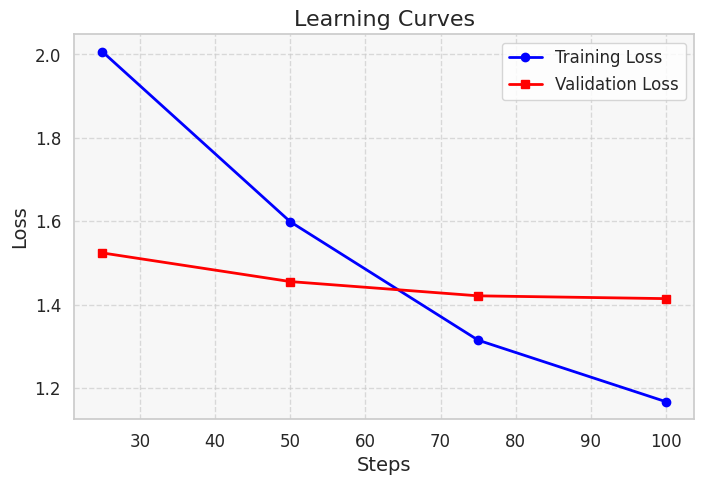

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")

# Plot learning curves
logs = trainer.state.log_history
steps = [log["step"] for log in logs if "loss" in log]
train_loss = [log["loss"] for log in logs if "loss" in log]
eval_loss = [log["eval_loss"] for log in logs if "eval_loss" in log]

plt.figure(figsize=(8, 5))
plt.plot(steps, train_loss, 'o-', color='blue', label='Training Loss', linewidth=2, markersize=6)
plt.plot(steps, eval_loss, 's-', color='red', label='Validation Loss', linewidth=2, markersize=6)

plt.xlabel('Steps', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.title('Learning Curves', fontsize=16)
plt.legend(fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.gca().set_facecolor('#f7f7f7')
plt.show()

In [25]:
# Check CUDA memory after training
after_training = check_cuda_memory()

 7.357GB  reserved of  21.975GB  VRAM


In [26]:
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - before_training, 3)
used_percentage = round(used_memory         /max_memory*100, 3)
lora_percentage = round(used_memory_for_lora/max_memory*100, 3)

print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training.")
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

190.8265 seconds used for training.
3.18 minutes used for training.
Peak reserved memory = 7.357 GB.
Peak reserved memory for training = 1.451 GB.
Peak reserved memory % of max memory = 33.479 %.
Peak reserved memory for training % of max memory = 6.603 %.


### Save Fine-Tuned Model

In [27]:
model.save_pretrained_merged(f"models/{model_name}", tokenizer, save_method="merged_16bit")

Unsloth: Merging 4bit and LoRA weights to 16bit...
Unsloth: Will use up to 15.03 out of 31.05 RAM for saving.


100%|██████████| 32/32 [00:04<00:00,  6.47it/s]


Unsloth: Saving tokenizer... Done.
Unsloth: Saving model... This might take 5 minutes for Llama-7b...
Done.


In [28]:
# Flush CUDA memory
import gc
torch.cuda.empty_cache()
gc.collect()

0

---